# VoltIA — Selección y entrenamiento del modelo de IA
**Equipo Kilowatt · Ruta 3: Innovación con IoT + IA (2026)**

Flujo: ESP32 (Wokwi) → MQTT → Adafruit IO (feeds `voltaje`, `corriente`, `potencia`, `energia`, `estado`, `aparato`) → **este notebook**.

**Decisiones de diseño**
1. **El estado del consumo NO se delega a la IA.** `NORMAL`, `CONSUMO_ALTO`, `SOBRECARGA` y `VOLTAJE_ANOMALO` son reglas de seguridad fijas que el ESP32 aplica al instante, sin depender de internet. Solo verificamos que un Árbol de Decisión *redescubre* esos umbrales a partir de los datos (sección 4).
2. **La IA se usa donde sí aporta: reconocer qué aparato está consumiendo** (monitoreo no intrusivo de cargas, NILM). Aparatos de potencia parecida no se separan con un umbral; hay que combinar potencia, factor de potencia y potencia reactiva.
3. **El modelo no se elige "a dedo":** se comparan 8 algoritmos con el mismo protocolo y se aplica una regla de selección fijada antes de ver los resultados (sección 5).
4. **Validación sin fugas:** las lecturas consecutivas de un mismo aparato son casi idénticas; si se reparten al azar entre entrenamiento y prueba, la exactitud se infla. Por eso se valida por **episodios completos** (`StratifiedGroupKFold`).

In [1]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests, getpass, joblib
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

FEEDS = ['voltaje', 'corriente', 'potencia', 'energia', 'estado', 'aparato']
SEMILLA = 42

## 1. Obtener los datos
**Opción A (recomendada):** descargar desde la API de Adafruit IO. La clave se pide oculta y no queda guardada en el notebook.

**Opción B:** subir los CSV de cada feed (Adafruit IO → feed → *Download Data*), o los que están en la carpeta `datos/` del proyecto.

In [2]:
# OPCIÓN A: API de Adafruit IO
AIO_USER = 'Ludwin1611'
# Los feeds de VoltIA son públicos: no hace falta clave.
# Si tus feeds son privados, usa: AIO_KEY = getpass.getpass('AIO Key (oculta): ')
AIO_KEY = ''
CABECERAS = {'X-AIO-Key': AIO_KEY} if AIO_KEY else {}

def descargar_feed(feed, maximo=5000):
    url = f'https://io.adafruit.com/api/v2/{AIO_USER}/feeds/{feed}/data'
    filas, params = [], {'limit': 1000}
    while len(filas) < maximo:
        r = requests.get(url, headers=CABECERAS, params=params, timeout=30)
        r.raise_for_status()
        lote = r.json()
        if not lote:
            break
        filas += lote
        params['end_time'] = lote[-1]['created_at']
        if len(lote) < 1000:
            break
    df = pd.DataFrame(filas)[['created_at', 'value']].drop_duplicates()
    return df.rename(columns={'value': feed})

crudos = {f: descargar_feed(f) for f in FEEDS}
{f: len(d) for f, d in crudos.items()}

{'voltaje': 442,
 'corriente': 442,
 'potencia': 442,
 'energia': 442,
 'estado': 442,
 'aparato': 303}

In [3]:
# OPCIÓN B: subir los CSV (ejecutar solo si no se usó la opción A)
# from google.colab import files
# subidos = files.upload()   # seleccionar voltaje.csv, corriente.csv, potencia.csv, energia.csv, estado.csv, aparato.csv
# crudos = {}
# for f in FEEDS:
#     nombre = [n for n in subidos if n.lower().startswith(f)][0]
#     d = pd.read_csv(nombre)
#     col = 'value' if 'value' in d.columns else f
#     crudos[f] = d[['created_at', col]].rename(columns={col: f})

## 2. Unificar los feeds y crear variables
El ESP32 publica los 6 valores de cada lectura casi al mismo tiempo; se emparejan por la marca de tiempo más cercana (tolerancia de 5 s).

Variables derivadas (ingeniería de características):
- **Potencia aparente** $S = V \cdot I$ (VA)
- **Factor de potencia** $fp = P / S$: los aparatos resistivos (plancha, olla) tienen $fp \approx 1$; los de motor (refrigeradora, aire) tienen $fp < 0.9$.
- **Potencia reactiva** $Q = \sqrt{S^2 - P^2}$ (VAr)
- **Cambio de potencia** $\Delta P$ respecto a la lectura anterior: un aparato que se enciende produce un salto característico.

In [4]:
for f, d in crudos.items():
    d['created_at'] = pd.to_datetime(d['created_at'], utc=True)
    crudos[f] = d.sort_values('created_at')

df = crudos['potencia']
for f in ['voltaje', 'corriente', 'energia', 'estado', 'aparato']:
    df = pd.merge_asof(df, crudos[f], on='created_at', direction='nearest', tolerance=pd.Timedelta('5s'))

df = df.dropna(subset=['voltaje', 'corriente', 'potencia', 'estado']).reset_index(drop=True)
for c in ['voltaje', 'corriente', 'potencia', 'energia']:
    df[c] = pd.to_numeric(df[c])
df['created_at'] = df['created_at'].dt.tz_convert('America/El_Salvador')
df['hora'] = df['created_at'].dt.hour
df['aparente'] = (df['voltaje'] * df['corriente']).round(1)
df['fp'] = (df['potencia'] / df['aparente']).clip(0, 1).round(3)
df['reactiva'] = np.sqrt((df['aparente']**2 - df['potencia']**2).clip(lower=0)).round(1)
df['delta_p'] = df['potencia'].diff().fillna(0).round(1)
df.insert(0, 'id', range(1, len(df) + 1))
print(f'Registros unificados: {len(df)}  |  con etiqueta de aparato: {df["aparato"].notna().sum()}')
df.head(10)

Registros unificados: 442  |  con etiqueta de aparato: 303


,id,created_at,potencia,voltaje,corriente,energia,estado,aparato,hora,aparente,fp,reactiva,delta_p
0,1,2026-10-16 22:05:15-06:00,88.1,118.1,0.82,0.00037,NORMAL,NaN,22,96.8,0.910,40.1,0.0
1,2,2026-10-16 22:05:30-06:00,102.4,117.8,0.94,0.00079,NORMAL,NaN,22,110.7,0.925,42.1,14.3
2,3,2026-10-16 22:05:45-06:00,101.4,117.8,0.90,0.00122,NORMAL,NaN,22,106.0,0.957,30.9,-1.0
3,4,2026-10-16 22:06:00-06:00,3500.0,149.7,25.64,0.01580,VOLTAJE_ANOMALO,NaN,22,3838.3,0.912,1575.6,3398.6
4,5,2026-10-16 22:06:15-06:00,353.2,118.7,3.12,0.01727,NORMAL,NaN,22,370.3,0.954,111.2,-3146.8
5,6,2026-10-16 22:06:30-06:00,3407.7,118.1,31.44,0.03147,SOBRECARGA,NaN,22,3713.1,0.918,1474.7,3054.5
6,7,2026-10-16 22:06:45-06:00,1529.1,118.7,14.09,0.03784,CONSUMO_ALTO,NaN,22,1672.5,0.914,677.6,-1878.6
7,8,2026-10-16 22:07:59-06:00,3500.0,118.3,32.39,0.01458,SOBRECARGA,NaN,22,3831.7,0.913,1559.5,1970.9
8,9,2026-10-16 22:08:13-06:00,73.2,118.2,0.64,0.01489,NORMAL,NaN,22,75.6,0.968,18.9,-3426.8
9,10,2026-10-16 22:08:28-06:00,1218.2,118.5,11.68,0.01996,NORMAL,NaN,22,1384.1,0.880,657.1,1145.0


## 3. Análisis exploratorio (EDA)

In [5]:
print(df[['voltaje', 'corriente', 'potencia', 'fp']].describe().round(2))
print('\nEstados:'); print(df['estado'].value_counts())
print('\nAparatos:'); print(df['aparato'].value_counts())

       voltaje  corriente  potencia      fp
count   442.00     442.00    442.00  442.00
mean    119.79      12.05   1349.24    0.92
std       4.44       9.85   1116.12    0.04
min      96.80       0.64     70.40    0.83
25%     118.62       3.05    340.12    0.89
50%     120.00      12.31   1390.75    0.93
75%     121.20      17.22   1995.75    0.96
max     149.70      47.29   4998.10    1.00

Estados:
estado
NORMAL             248
CONSUMO_ALTO        93
SOBRECARGA          77
VOLTAJE_ANOMALO     24
Name: count, dtype: int64

Aparatos:
aparato
Aire acondicionado    77
Refrigeradora         60
Secadora de pelo      39
Plancha               27
Televisor             26
Microondas            26
Olla arrocera         25
Base                  23
Name: count, dtype: int64


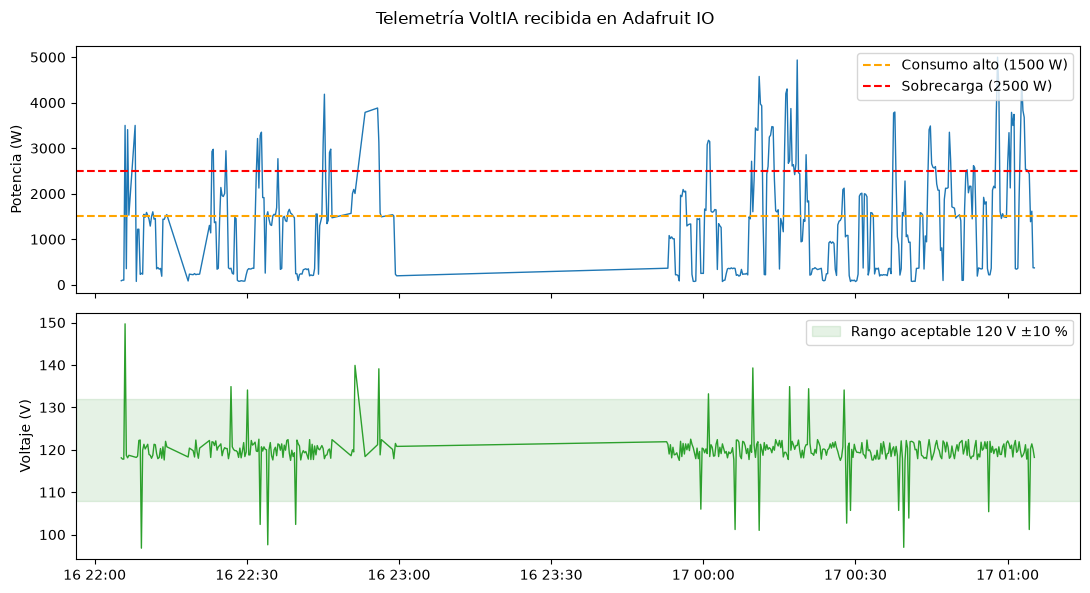

In [6]:
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax[0].plot(df['created_at'], df['potencia'], lw=1)
ax[0].axhline(1500, ls='--', c='orange', label='Consumo alto (1500 W)')
ax[0].axhline(2500, ls='--', c='red', label='Sobrecarga (2500 W)')
ax[0].set_ylabel('Potencia (W)'); ax[0].legend(loc='upper right')
ax[1].plot(df['created_at'], df['voltaje'], lw=1, c='tab:green')
ax[1].axhspan(108, 132, alpha=0.1, color='green', label='Rango aceptable 120 V ±10 %')
ax[1].set_ylabel('Voltaje (V)'); ax[1].legend(loc='upper right')
plt.suptitle('Telemetría VoltIA recibida en Adafruit IO'); plt.tight_layout(); plt.show()

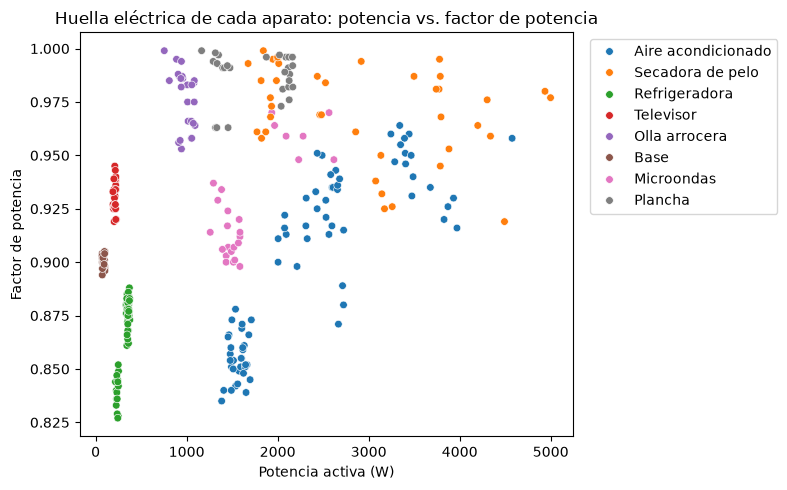

In [7]:
dfa = df.dropna(subset=['aparato'])
plt.figure(figsize=(8, 5))
sns.scatterplot(data=dfa, x='potencia', y='fp', hue='aparato', s=30)
plt.title('Huella eléctrica de cada aparato: potencia vs. factor de potencia')
plt.xlabel('Potencia activa (W)'); plt.ylabel('Factor de potencia')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left'); plt.tight_layout(); plt.show()

## 4. Estado del consumo: reglas del ESP32 (sin IA)
Los umbrales se fijan por seguridad eléctrica (120 V ± 10 %, 1500 W y 2500 W/20 A) y deben aplicarse en el dispositivo aunque se caiga internet. Un modelo aprendido sería **redundante** (copiaría la regla) y **más riesgoso** (podría equivocarse en un caso crítico).

Como verificación, un Árbol de Decisión entrenado solo con los datos debería encontrar umbrales cercanos a los programados:

In [8]:
arbol_reglas = DecisionTreeClassifier(max_depth=3, random_state=SEMILLA).fit(df[['voltaje', 'potencia']], df['estado'])
print(export_text(arbol_reglas, feature_names=['voltaje', 'potencia'], decimals=0))
print('Coincidencia con las reglas del ESP32:', round(accuracy_score(df['estado'], arbol_reglas.predict(df[['voltaje', 'potencia']])) * 100, 1), '%')

|--- potencia <= 1499
|   |--- voltaje <= 112
|   |   |--- class: VOLTAJE_ANOMALO
|   |--- voltaje >  112
|   |   |--- voltaje <= 128
|   |   |   |--- class: NORMAL
|   |   |--- voltaje >  128
|   |   |   |--- class: VOLTAJE_ANOMALO
|--- potencia >  1499
|   |--- potencia <= 2190
|   |   |--- voltaje <= 128
|   |   |   |--- class: CONSUMO_ALTO
|   |   |--- voltaje >  128
|   |   |   |--- class: VOLTAJE_ANOMALO
|   |--- potencia >  2190
|   |   |--- voltaje <= 128
|   |   |   |--- class: SOBRECARGA
|   |   |--- voltaje >  128
|   |   |   |--- class: VOLTAJE_ANOMALO

Coincidencia con las reglas del ESP32: 98.6 %


## 5. Reconocimiento del aparato: selección del modelo
**Variables de entrada (7):** potencia, corriente, voltaje, potencia aparente, factor de potencia, potencia reactiva y ΔP.
**Salida:** `aparato` (electrodoméstico que domina el consumo).

**Protocolo:**
- Se agrupan las lecturas en **episodios**: tramos consecutivos con el mismo aparato. Cada episodio queda completo en entrenamiento o en prueba.
- Prueba final: 20 % de los episodios, separados al inicio y que no se tocan hasta el final.
- Comparación: validación cruzada estratificada y agrupada de 5 particiones sobre el 80 % restante, con las mismas particiones para todos los modelos.
- Métrica principal: **F1 macro** (promedio por clase; no deja que las clases frecuentes oculten errores en las raras).

**Regla de selección (fijada antes de ver resultados):** se elige el modelo con mayor F1 macro medio. Si otro modelo está a menos de 0.01 y es más simple o más explicable, se prefiere ese.

In [9]:
COLS = ['potencia', 'corriente', 'voltaje', 'aparente', 'fp', 'reactiva', 'delta_p']
dfa = df.dropna(subset=['aparato'])
dfa = dfa[dfa['aparato'] != 'Manual'].reset_index(drop=True)
dfa['episodio'] = (dfa['aparato'] != dfa['aparato'].shift()).cumsum()
X, y, grupos = dfa[COLS], dfa['aparato'], dfa['episodio']
print(f'Lecturas: {len(dfa)}  |  Episodios: {grupos.nunique()}  |  Clases: {y.nunique()}')

# Separar el 20 % de los episodios como prueba final
sgkf_test = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
idx_tr, idx_te = next(sgkf_test.split(X, y, grupos))
X_tr, X_te, y_tr, y_te, g_tr = X.iloc[idx_tr], X.iloc[idx_te], y.iloc[idx_tr], y.iloc[idx_te], grupos.iloc[idx_tr]
print(f'Entrenamiento: {len(X_tr)} lecturas  |  Prueba: {len(X_te)} lecturas (episodios nunca vistos)')
k = int(max(2, min(5, y_tr.value_counts().min())))
CV = list(StratifiedGroupKFold(n_splits=k, shuffle=True, random_state=SEMILLA).split(X_tr, y_tr, g_tr))

Lecturas: 303  |  Episodios: 93  |  Clases: 8
Entrenamiento: 246 lecturas  |  Prueba: 57 lecturas (episodios nunca vistos)


In [10]:
CANDIDATOS = {
    'Línea base (clase más frecuente)': DummyClassifier(strategy='most_frequent'),
    'Regresión logística': make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight='balanced')),
    'k vecinos más cercanos (k=5)': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    'SVM (kernel RBF)': make_pipeline(StandardScaler(), SVC(class_weight='balanced', random_state=SEMILLA)),
    'Árbol de Decisión': DecisionTreeClassifier(class_weight='balanced', random_state=SEMILLA),
    'Random Forest': RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=SEMILLA, n_jobs=-1),
    'Extra Trees': ExtraTreesClassifier(n_estimators=300, class_weight='balanced', random_state=SEMILLA, n_jobs=-1),
    'Gradient Boosting (Hist)': HistGradientBoostingClassifier(class_weight='balanced', random_state=SEMILLA),
}
SIMPLICIDAD = ['Árbol de Decisión', 'Random Forest', 'Regresión logística', 'k vecinos más cercanos (k=5)',
               'Extra Trees', 'Gradient Boosting (Hist)', 'SVM (kernel RBF)']  # de más a menos explicable

filas = []
for nombre, modelo in CANDIDATOS.items():
    t0 = time.time()
    r = cross_validate(modelo, X_tr, y_tr, cv=CV, scoring=['f1_macro', 'accuracy'])
    filas.append({'modelo': nombre, 'f1_macro': r['test_f1_macro'].mean(), 'f1_std': r['test_f1_macro'].std(),
                  'accuracy': r['test_accuracy'].mean(), 'segundos': time.time() - t0})
comparacion = pd.DataFrame(filas).sort_values('f1_macro', ascending=False).reset_index(drop=True)
print(comparacion.round(3).to_string(index=False))

                          modelo  f1_macro  f1_std  accuracy  segundos
                   Random Forest     0.885   0.055     0.898     0.696
                     Extra Trees     0.874   0.077     0.906     0.584
        Gradient Boosting (Hist)     0.826   0.055     0.849     2.246
               Árbol de Decisión     0.808   0.066     0.824     0.011
             Regresión logística     0.796   0.078     0.825     0.028
                SVM (kernel RBF)     0.750   0.075     0.793     0.017
    k vecinos más cercanos (k=5)     0.731   0.036     0.801     0.014
Línea base (clase más frecuente)     0.051   0.005     0.256     0.008


Mejor F1 macro: Random Forest (0.885)
Modelo elegido según la regla: Random Forest


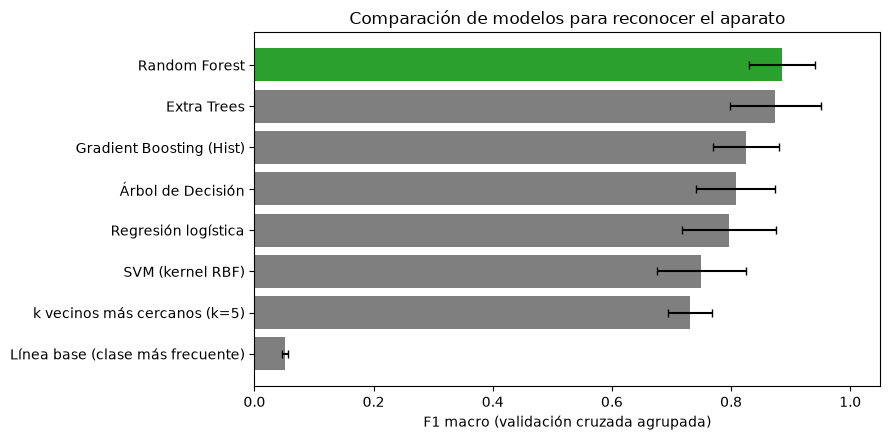

In [11]:
mejor = comparacion.iloc[0]
empatados = comparacion[(mejor['f1_macro'] - comparacion['f1_macro'] < 0.01) & comparacion['modelo'].isin(SIMPLICIDAD)]
ELEGIDO = min(empatados['modelo'], key=SIMPLICIDAD.index) if len(empatados) else mejor['modelo']
print(f'Mejor F1 macro: {mejor["modelo"]} ({mejor["f1_macro"]:.3f})')
print(f'Modelo elegido según la regla: {ELEGIDO}')

plt.figure(figsize=(9, 4.5))
orden = comparacion.sort_values('f1_macro')
colores = ['tab:green' if m == ELEGIDO else 'tab:gray' for m in orden['modelo']]
plt.barh(orden['modelo'], orden['f1_macro'], xerr=orden['f1_std'], color=colores, capsize=3)
plt.xlabel('F1 macro (validación cruzada agrupada)'); plt.xlim(0, 1.05)
plt.title('Comparación de modelos para reconocer el aparato'); plt.tight_layout(); plt.show()

## 6. Ajuste de hiperparámetros del modelo elegido
Búsqueda en rejilla con las mismas particiones agrupadas, optimizando F1 macro.

In [12]:
REJILLAS = {
    'Random Forest': {'n_estimators': [100, 300, 500], 'max_depth': [None, 6, 10], 'min_samples_leaf': [1, 2, 4], 'max_features': ['sqrt', None]},
    'Extra Trees': {'n_estimators': [100, 300, 500], 'max_depth': [None, 6, 10], 'min_samples_leaf': [1, 2, 4]},
    'Gradient Boosting (Hist)': {'learning_rate': [0.05, 0.1, 0.2], 'max_depth': [None, 4, 8], 'max_iter': [100, 300]},
    'Árbol de Decisión': {'max_depth': [None, 4, 6, 8], 'min_samples_leaf': [1, 2, 4]},
    'SVM (kernel RBF)': {'svc__C': [1, 10, 100], 'svc__gamma': ['scale', 0.1, 1]},
    'k vecinos más cercanos (k=5)': {'kneighborsclassifier__n_neighbors': [3, 5, 9, 15]},
    'Regresión logística': {'logisticregression__C': [0.1, 1, 10]},
}
busqueda = GridSearchCV(CANDIDATOS[ELEGIDO], REJILLAS.get(ELEGIDO, {}), scoring='f1_macro', cv=CV, n_jobs=-1)
busqueda.fit(X_tr, y_tr)
modelo_final = busqueda.best_estimator_
print('Mejores hiperparámetros:', busqueda.best_params_)
print(f'F1 macro en validación cruzada: {busqueda.best_score_:.3f}')

Mejores hiperparámetros: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 500}
F1 macro en validación cruzada: 0.891


## 7. Evaluación final (episodios nunca vistos)

Exactitud: 0.930  |  F1 macro: 0.918
                    precision    recall  f1-score   support

Aire acondicionado       0.88      1.00      0.93        14
              Base       1.00      1.00      1.00         4
        Microondas       1.00      1.00      1.00         5
     Olla arrocera       0.83      1.00      0.91         5
           Plancha       0.83      0.83      0.83         6
     Refrigeradora       1.00      1.00      1.00        12
  Secadora de pelo       1.00      0.50      0.67         6
         Televisor       1.00      1.00      1.00         5

          accuracy                           0.93        57
         macro avg       0.94      0.92      0.92        57
      weighted avg       0.94      0.93      0.92        57



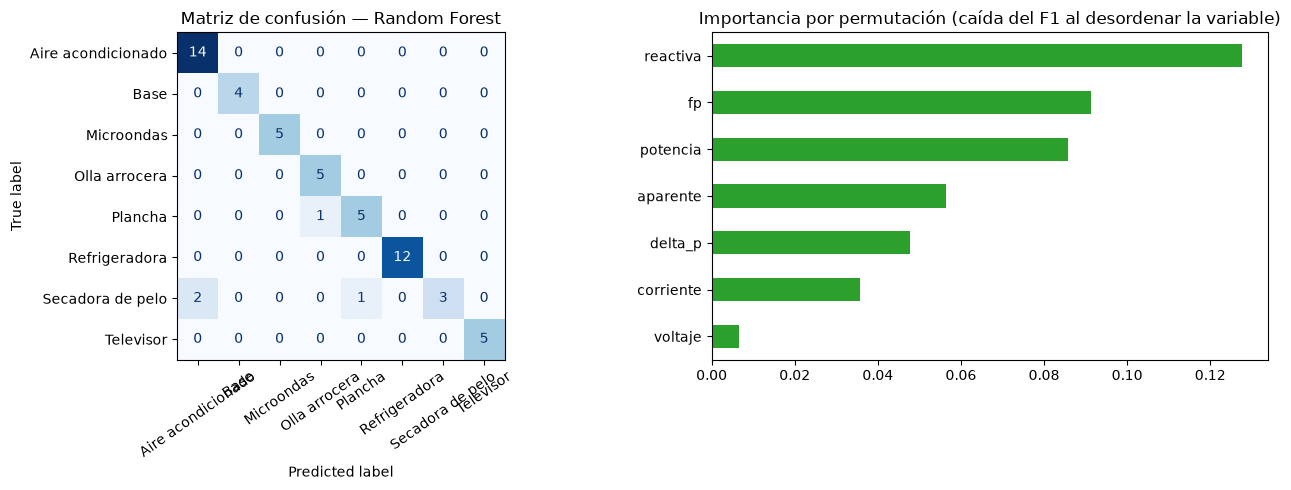

In [13]:
y_pred = modelo_final.predict(X_te)
ACC, F1 = accuracy_score(y_te, y_pred), f1_score(y_te, y_pred, average='macro')
print(f'Exactitud: {ACC:.3f}  |  F1 macro: {F1:.3f}')
print(classification_report(y_te, y_pred, zero_division=0))

pi = permutation_importance(modelo_final, X_te, y_te, scoring='f1_macro', n_repeats=20, random_state=SEMILLA)
importancias = pd.Series(pi.importances_mean, index=COLS).sort_values(ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={'width_ratios': [1.3, 1]})
etiquetas = sorted(y.unique())
ConfusionMatrixDisplay(confusion_matrix(y_te, y_pred, labels=etiquetas), display_labels=etiquetas).plot(
    ax=ax[0], cmap='Blues', xticks_rotation=35, colorbar=False)
ax[0].set_title(f'Matriz de confusión — {ELEGIDO}')
importancias.sort_values().plot.barh(ax=ax[1], color='tab:green')
ax[1].set_title('Importancia por permutación (caída del F1 al desordenar la variable)')
plt.tight_layout(); plt.show()

## 8. Probar el modelo con lecturas nuevas

In [14]:
nuevas = pd.DataFrame([
    {'voltaje': 120.4, 'corriente': 2.4, 'potencia': 230.0},
    {'voltaje': 119.1, 'corriente': 11.4, 'potencia': 1330.0},
    {'voltaje': 118.6, 'corriente': 10.9, 'potencia': 1290.0},
    {'voltaje': 119.0, 'corriente': 13.6, 'potencia': 1620.0},
])
nuevas['aparente'] = nuevas['voltaje'] * nuevas['corriente']
nuevas['fp'] = (nuevas['potencia'] / nuevas['aparente']).clip(0, 1)
nuevas['reactiva'] = np.sqrt((nuevas['aparente']**2 - nuevas['potencia']**2).clip(lower=0))
nuevas['delta_p'] = nuevas['potencia'] - 230
nuevas['aparato_predicho'] = modelo_final.predict(nuevas[COLS])
nuevas.round(2)

,voltaje,corriente,potencia,aparente,fp,reactiva,delta_p,aparato_predicho
0,120.4,2.4,230.0,288.96,0.80,174.92,0.0,Refrigeradora
1,119.1,11.4,1330.0,1357.74,0.98,273.05,1100.0,Plancha
2,118.6,10.9,1290.0,1292.74,1.00,84.12,1060.0,Plancha
3,119.0,13.6,1620.0,1618.40,1.00,0.00,1390.0,Plancha


## 9. Exportar el dataset propio y el modelo

In [15]:
df.to_csv('dataset_voltia.csv', index=False)
joblib.dump({'modelo': modelo_final, 'nombre': ELEGIDO, 'columnas': COLS}, 'modelo_voltia_aparatos.joblib')
print(df[['id', 'created_at', 'voltaje', 'corriente', 'potencia', 'fp', 'estado', 'aparato']].head(8).to_string(index=False))
# from google.colab import files; files.download('dataset_voltia.csv')

 id                created_at  voltaje  corriente  potencia    fp          estado aparato
  1 2026-10-16 22:05:15-06:00    118.1       0.82      88.1 0.910          NORMAL     NaN
  2 2026-10-16 22:05:30-06:00    117.8       0.94     102.4 0.925          NORMAL     NaN
  3 2026-10-16 22:05:45-06:00    117.8       0.90     101.4 0.957          NORMAL     NaN
  4 2026-10-16 22:06:00-06:00    149.7      25.64    3500.0 0.912 VOLTAJE_ANOMALO     NaN
  5 2026-10-16 22:06:15-06:00    118.7       3.12     353.2 0.954          NORMAL     NaN
  6 2026-10-16 22:06:30-06:00    118.1      31.44    3407.7 0.918      SOBRECARGA     NaN
  7 2026-10-16 22:06:45-06:00    118.7      14.09    1529.1 0.914    CONSUMO_ALTO     NaN
  8 2026-10-16 22:07:59-06:00    118.3      32.39    3500.0 0.913      SOBRECARGA     NaN
